# Diabetic Retinopathy Grading from Fundus Images

This notebook **creates the deployed model** (`models/diabetic_retinopathy_mobilenet.h5`) and evaluates it on held-out test images.

**Task:** classify a retinal fundus photograph into one of 5 diabetic retinopathy (DR) grades:

| Label | Grade | Meaning |
|---|---|---|
| 0 | No_DR | no retinopathy |
| 1 | Mild | microaneurysms only |
| 2 | Moderate | more than mild, less than severe |
| 3 | Severe | many haemorrhages, venous beading; refer urgently |
| 4 | Proliferate_DR | new vessel growth; sight-threatening |

**Pipeline:**
1. Data acquisition: APTOS 2019 + an EyePACS sample, split so test images are never trained on
2. Data preprocessing: resize, Gaussian filter, scaling, augmentation, class weights
3. Model creation: MobileNetV2 transfer learning with regularization, Adam, early stopping, LR scheduling
4. Model testing: accuracy, loss, precision, recall, F1, confusion matrices on two held-out test sets
5. Prediction functions: the same `src/prediction.py` code the API uses

The preprocessing and model code lives in `src/` (`preprocessing.py`, `model.py`, `prediction.py`) and is shared with the API, so the notebook, training and serving all use identical steps.

In [1]:
import inspect
import json
import shutil
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

from src.config import CLASS_NAMES, IMG_SIZE, MODEL_PATH, SEED, SPLITS_DIR
from src.model import build_model, compile_model, load_model, save_model, unfreeze_top
from src.preprocessing import apply_gaussian, image_stats, load_image_rgb, preprocess_image

keras.utils.set_random_seed(SEED)
NAMES = [CLASS_NAMES[i] for i in range(5)]
pd.set_option("display.precision", 3)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("Project root:", ROOT)

/Users/ntagungiraalirashid/Documents/mlp-summative/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow 2.17.1 | Keras 3.10.0
Project root: /Users/ntagungiraalirashid/Documents/mlp-summative


## 1. Data acquisition

Two public fundus datasets, both labelled with the same 0–4 grade:

- **APTOS 2019** (Kaggle *APTOS 2019 Blindness Detection*, via Hugging Face `bumbledeep/aptos`): 3,662 images, 224×224. Downloaded by `scripts/download_data.py`.
- **EyePACS** (Kaggle 2015 *Diabetic Retinopathy Detection*, via Hugging Face `ctmedtech/EYEPACS`): 35,108 images from many clinics and cameras. A class-balanced sample is used so that the model sees more than one camera type.

`scripts/build_combined.py` builds the splits (seed 42, reproducible):

- **APTOS:** 15 % of each class is held out as `aptos_test`.
- **EyePACS:** each patient has a left and a right eye photo, which look very similar. Patients are split 85/15 *before* sampling, so no patient appears in both train and test. Then 400 images per class go to training and 60 per class to `eyepacs_test`.
- **`mixed_train`** = APTOS train + EyePACS train. This is what the model is trained on.

The two **test sets are never used for training, validation or model selection**. All reported scores come from them.

grade,No_DR,Mild,Moderate,Severe,Proliferate_DR,total
split,,,,,,
aptos_test,271,56,150,29,44,550
aptos_train,1534,314,849,164,251,3112
eyepacs_test,60,60,60,60,60,300
eyepacs_train,400,400,400,400,400,2000


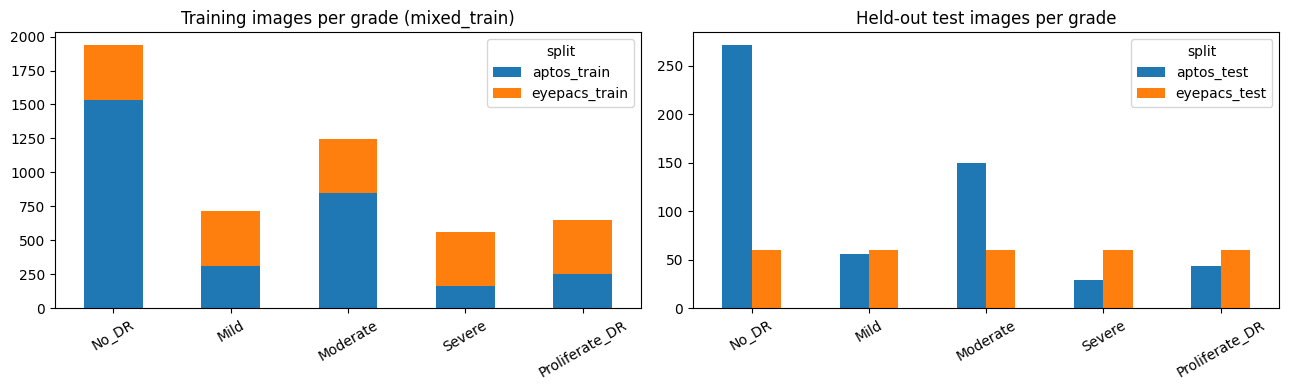

In [2]:
manifest = pd.read_csv(SPLITS_DIR / "split_manifest.csv")
manifest["grade"] = manifest["label"].map(CLASS_NAMES)
counts = manifest.pivot_table(index="split", columns="grade", values="image", aggfunc="count").reindex(columns=NAMES)
counts["total"] = counts.sum(axis=1)
display(counts)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.loc[["aptos_train", "eyepacs_train"], NAMES].T.plot(kind="bar", stacked=True, ax=ax[0],
                                                           title="Training images per grade (mixed_train)")
counts.loc[["aptos_test", "eyepacs_test"], NAMES].T.plot(kind="bar", ax=ax[1], title="Held-out test images per grade")
for a in ax:
    a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

APTOS is heavily imbalanced: almost half the images are No_DR and Severe has only ~190. The balanced EyePACS sample adds 400 images to every grade, which roughly triples the Severe and Proliferate_DR training data. The remaining imbalance is handled with class weights (section 2).

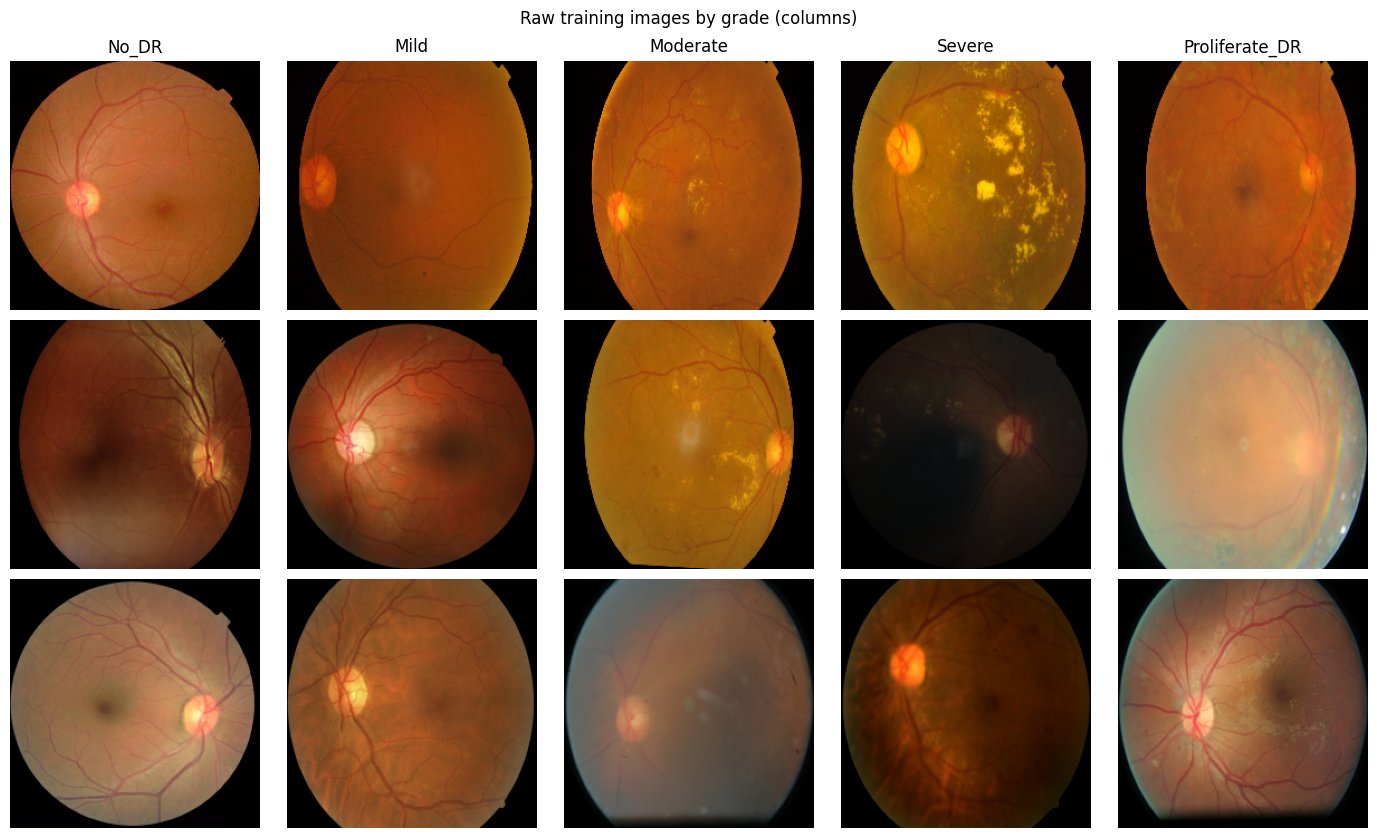

In [3]:
def example_paths(split, per_class=3):
    out = []
    for name in NAMES:
        files = sorted((SPLITS_DIR / split / name).glob("*"))[:per_class]
        out += [(f, name) for f in files]
    return out

fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
for col, name in enumerate(NAMES):
    files = sorted((SPLITS_DIR / "mixed_train" / name).glob("*"))
    picks = [files[0], files[len(files) // 2], files[-1]]   # APTOS and EyePACS examples
    for row, f in enumerate(picks):
        axes[row, col].imshow(load_image_rgb(f)); axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(name)
plt.suptitle("Raw training images by grade (columns)"); plt.tight_layout(); plt.show()

## 2. Data preprocessing

Every image (training, test, API upload, retraining upload) goes through the same `preprocess_image` function in `src/preprocessing.py`:

1. **Load as RGB** (PNG/JPEG, any size)
2. **Resize to 224×224** with area interpolation, the input size of MobileNetV2
3. **Gaussian filter** (Ben Graham's method from the Kaggle DR competition): `4·img − 4·blur(img) + 128`. It removes lighting differences between cameras and makes lesions (haemorrhages, exudates) stand out
4. **Scale pixels to [0, 1]** (float32). The model's first layer then rescales to [−1, 1], as MobileNetV2 expects

In [4]:
print(inspect.getsource(apply_gaussian))
print(inspect.getsource(preprocess_image))

def apply_gaussian(img: np.ndarray, ksize: int = 5) -> np.ndarray:
    """Match the APTOS Gaussian-filtered Kaggle variant."""
    if ksize % 2 == 0:
        ksize += 1
    return cv2.GaussianBlur(img, (ksize, ksize), 0)

def preprocess_image(
    source: Union[str, Path, bytes, np.ndarray],
    *,
    size: int = IMG_SIZE,
    gaussian: bool = True,
) -> np.ndarray:
    """Return float32 tensor (size, size, 3) in [0, 1]."""
    img = load_image_rgb(source)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    if gaussian:
        img = apply_gaussian(img)
    return (img.astype(np.float32) / 255.0)



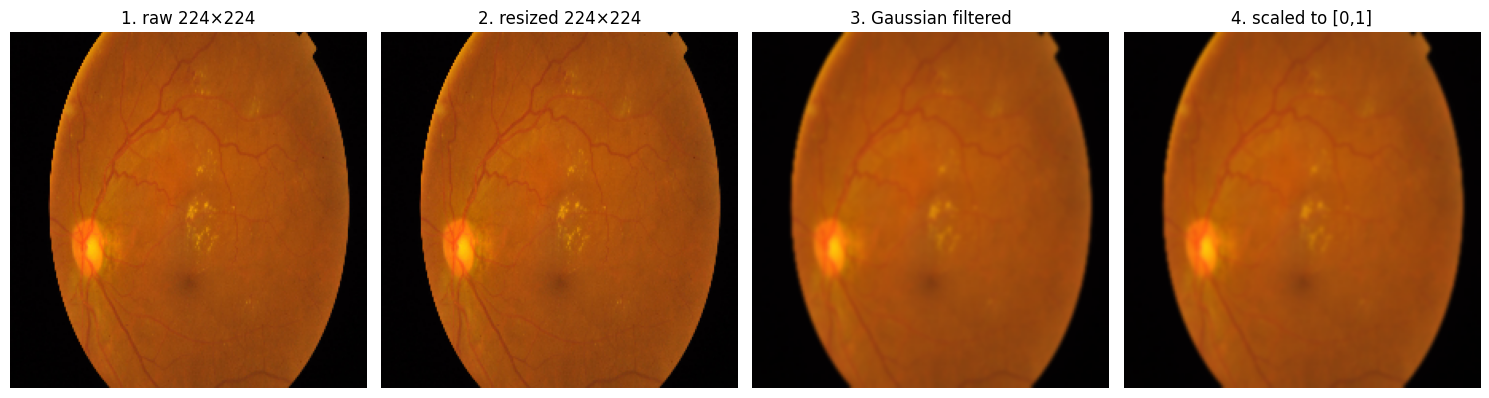

final tensor: (224, 224, 3) float32 range [0.00, 1.00]


In [5]:
f = sorted((SPLITS_DIR / "mixed_train" / "Moderate").glob("*"))[0]
raw = load_image_rgb(f)
resized = cv2.resize(raw, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
filtered = apply_gaussian(resized)
final = preprocess_image(f)

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, img, title in zip(ax, [raw, resized, filtered, final],
                         [f"1. raw {raw.shape[1]}×{raw.shape[0]}", "2. resized 224×224",
                          "3. Gaussian filtered", "4. scaled to [0,1]"]):
    a.imshow(img); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()
print("final tensor:", final.shape, final.dtype, f"range [{final.min():.2f}, {final.max():.2f}]")

### Feature exploration

Three simple image features, computed per image by `image_stats` and shown in the UI's *Visualizations* tab:

- **Brightness**: mean grey level
- **Green channel mean**: blood vessels and lesions show the most contrast in the green channel
- **Sharpness**: variance of the Laplacian, a focus/quality measure

,brightness,green_mean,sharpness
grade,,,
No_DR,61.220,52.877,255.190
Mild,69.879,57.311,272.086
Moderate,65.427,55.018,235.448
Severe,65.939,56.810,240.325
Proliferate_DR,67.223,57.420,240.576


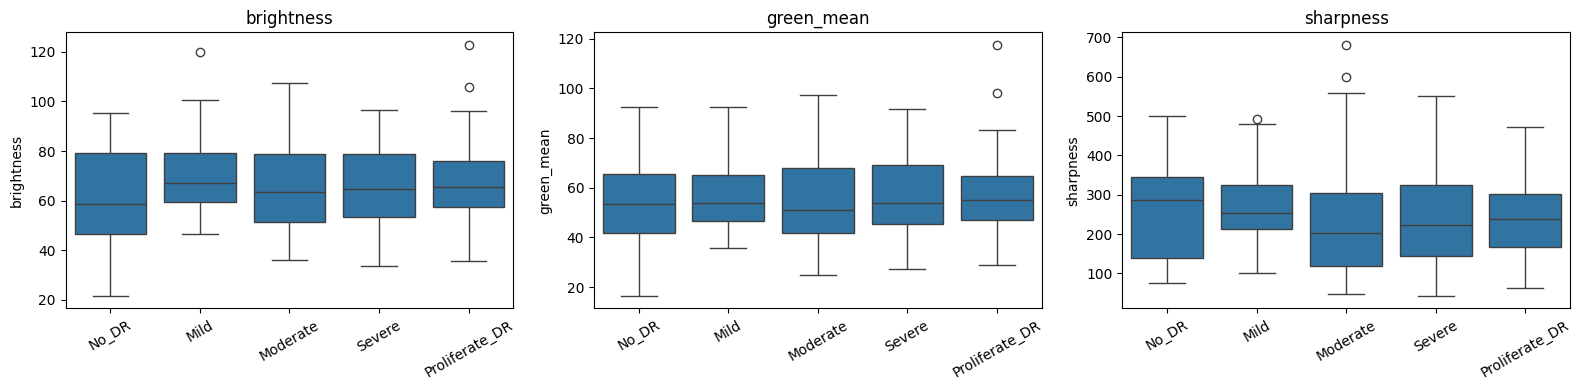

In [6]:
rows = []
for name in NAMES:
    for p in sorted((SPLITS_DIR / "aptos_train" / name).glob("*"))[:60]:
        s = image_stats(p); s["grade"] = name; rows.append(s)
feat = pd.DataFrame(rows)
display(feat.groupby("grade")[["brightness", "green_mean", "sharpness"]].mean().reindex(NAMES))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["brightness", "green_mean", "sharpness"]):
    sns.boxplot(data=feat, x="grade", y=col, order=NAMES, ax=a)
    a.set_title(col); a.tick_params(axis="x", rotation=30); a.set_xlabel("")
plt.tight_layout(); plt.show()

**What the features show:** the grades overlap heavily on all three. Brightness and green intensity vary as much between cameras and patients as between grades, and sharpness mostly reflects photo quality. No single global statistic separates the grades, because DR is graded from small local lesions. That is why a convolutional network that learns local patterns is used, and why the Gaussian filter (which removes global lighting differences) is part of preprocessing.

### Load the data

All three datasets go through `preprocess_image`. 20 % of `mixed_train` (stratified by grade) is held out as a **validation set** for early stopping and learning-rate scheduling. The test sets stay untouched until section 4.

In [7]:
EXTS = {".png", ".jpg", ".jpeg"}

def load_split(root):
    xs, ys, paths = [], [], []
    for label, name in CLASS_NAMES.items():
        for p in sorted((root / name).glob("*")):
            if p.suffix.lower() in EXTS:
                xs.append(preprocess_image(p)); ys.append(label); paths.append(p)
    return np.stack(xs), np.array(ys, dtype=np.int32), paths

t0 = time.time()
X, y, _ = load_split(SPLITS_DIR / "mixed_train")
X_aptos_test, y_aptos_test, aptos_test_paths = load_split(SPLITS_DIR / "aptos_test")
X_eye_test, y_eye_test, _ = load_split(SPLITS_DIR / "eyepacs_test")
print(f"loaded in {time.time() - t0:.0f}s")

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
del X
for name, arr in [("train", y_train), ("validation", y_val), ("APTOS test", y_aptos_test), ("EyePACS test", y_eye_test)]:
    print(f"{name:13} {len(arr):5} images  {dict(sorted(Counter(arr.tolist()).items()))}")

loaded in 8s


train          4089 images  {0: 1547, 1: 571, 2: 999, 3: 451, 4: 521}
validation     1023 images  {0: 387, 1: 143, 2: 250, 3: 113, 4: 130}
APTOS test      550 images  {0: 271, 1: 56, 2: 150, 3: 29, 4: 44}
EyePACS test    300 images  {0: 60, 1: 60, 2: 60, 3: 60, 4: 60}


### Class weights

Each grade's loss is weighted by `n_samples / (n_classes × n_in_grade)`, so mistakes on rare grades (Severe, Proliferate_DR) cost more than mistakes on No_DR.

In [8]:
counts_train = Counter(y_train.tolist())
class_weight = {c: len(y_train) / (5 * n) for c, n in sorted(counts_train.items())}
display(pd.Series({CLASS_NAMES[c]: w for c, w in class_weight.items()}, name="class weight").to_frame())

,class weight
No_DR,0.529
Mild,1.432
Moderate,0.819
Severe,1.813
Proliferate_DR,1.570


### Data augmentation

Applied to training batches only, freshly randomised every epoch. Fundus photos have no fixed orientation, so flips and full rotations do not change the grade. Zoom, brightness and contrast imitate differences between cameras. This is a regularization technique: the model never sees exactly the same image twice.

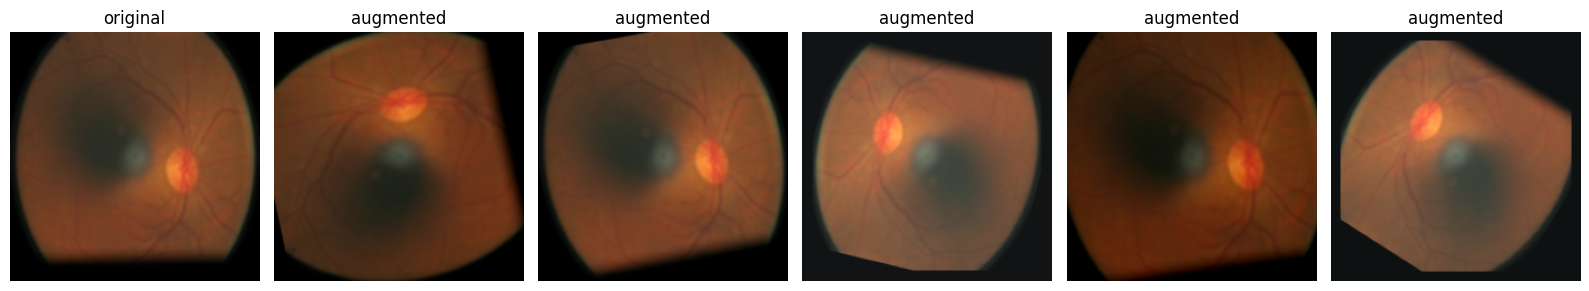

In [9]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.5, fill_mode="constant", fill_value=0.0, seed=SEED),   # up to ±180°
    layers.RandomZoom((-0.1, 0.1), fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomBrightness(0.1, value_range=(0.0, 1.0), seed=SEED),
    layers.RandomContrast(0.1, seed=SEED),
], name="augment")


class AugmentedBatches(keras.utils.PyDataset):
    # Shuffled, augmented batches from in-memory arrays; class weights passed as per-sample weights.
    def __init__(self, x, y, batch_size, weights, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.x, self.y, self.batch_size = x, y, batch_size
        self.sample_w = np.array([weights[int(c)] for c in y], dtype=np.float32)
        self.rng = np.random.default_rng(seed)
        self.order = self.rng.permutation(len(x))

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def __getitem__(self, i):
        idx = self.order[i * self.batch_size:(i + 1) * self.batch_size]
        xb = np.clip(np.asarray(augment(self.x[idx], training=True)), 0.0, 1.0)
        return xb, self.y[idx], self.sample_w[idx]

    def on_epoch_end(self):
        self.order = self.rng.permutation(len(self.x))


BATCH_SIZE = 32
train_batches = AugmentedBatches(X_train, y_train, BATCH_SIZE, class_weight)

sample = X_train[:1]
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
ax[0].imshow(sample[0]); ax[0].set_title("original")
for a in ax[1:]:
    a.imshow(np.clip(np.asarray(augment(sample, training=True))[0], 0, 1)); a.set_title("augmented")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Model creation

**Transfer learning** from **MobileNetV2** pretrained on ImageNet: a small, fast network (about 2.4 M parameters), which suits CPU serving behind an API.

Architecture (`src/model.py`): rescale to [−1, 1] → MobileNetV2 backbone → global average pooling → Dropout(0.3) → Dense(128, ReLU, L2 1e-4) → Dropout(0.3) → Dense(5, softmax).

Optimization techniques used:

| Technique | Setting |
|---|---|
| Pretrained model | MobileNetV2, ImageNet weights |
| Regularization | Dropout 0.3 (×2), L2 1e-4 on the dense layer, data augmentation |
| Optimizer | Adam: lr 1e-3 for the head, 1e-5 for fine-tuning |
| Early stopping | on validation loss, patience 6, restores the best weights |
| LR scheduling | ReduceLROnPlateau: halve the LR after 3 epochs without improvement |
| Class imbalance | class-weighted loss |
| Two-phase training | 1) train only the new head with the backbone frozen, 2) unfreeze the top 40 backbone layers and fine-tune |
| Hyperparameter tuning | data mix, augmentation and epoch budget compared on the test sets (section 4.3) |

In [10]:
print(inspect.getsource(build_model))
model = build_model(trainable_base=False, dropout=0.3, l2=1e-4)
compile_model(model, learning_rate=1e-3)
model.summary()

def build_model(
    *,
    num_classes: int = NUM_CLASSES,
    img_size: int = IMG_SIZE,
    trainable_base: bool = False,
    dropout: float = 0.3,
    l2: float = 1e-4,
) -> keras.Model:
    base = keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3),
        include_top=False,
        weights="imagenet",
    )
    base.trainable = trainable_base

    inputs = keras.Input(shape=(img_size, img_size, 3))
    # MobileNetV2 expects [-1, 1]
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(l2),
    )(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    model = keras.Model(inputs, outputs, name="dr_mobilenetv2")
    return model



Model: "dr_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
EPOCHS_HEAD, EPOCHS_FT, PATIENCE = 10, 20, 6

def callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=PATIENCE // 2),
    ]

print("=== Phase 1: frozen backbone, train the new head ===")
t0 = time.time()
hist1 = model.fit(train_batches, validation_data=(X_val, y_val), epochs=EPOCHS_HEAD,
                  callbacks=callbacks(), verbose=2)
print(f"phase 1: {time.time() - t0:.0f}s")

=== Phase 1: frozen backbone, train the new head ===
Epoch 1/10


128/128 - 16s - 124ms/step - accuracy: 0.4055 - loss: 1.5221 - sparse_acc: 0.4055 - val_accuracy: 0.4370 - val_loss: 1.2914 - val_sparse_acc: 0.4370 - learning_rate: 0.0010


Epoch 2/10


128/128 - 14s - 113ms/step - accuracy: 0.4825 - loss: 1.3358 - sparse_acc: 0.4825 - val_accuracy: 0.4985 - val_loss: 1.2327 - val_sparse_acc: 0.4985 - learning_rate: 0.0010


Epoch 3/10


128/128 - 15s - 115ms/step - accuracy: 0.5065 - loss: 1.2960 - sparse_acc: 0.5065 - val_accuracy: 0.4712 - val_loss: 1.2278 - val_sparse_acc: 0.4712 - learning_rate: 0.0010


... (11 outputs left out)

128/128 - 15s - 115ms/step - accuracy: 0.5640 - loss: 1.1732 - sparse_acc: 0.5640 - val_accuracy: 0.5562 - val_loss: 1.1478 - val_sparse_acc: 0.5562 - learning_rate: 0.0010


Epoch 10/10


128/128 - 16s - 125ms/step - accuracy: 0.5581 - loss: 1.1577 - sparse_acc: 0.5581 - val_accuracy: 0.4936 - val_loss: 1.1632 - val_sparse_acc: 0.4936 - learning_rate: 5.0000e-04


phase 1: 149s


In [12]:
print("=== Phase 2: fine-tune the top 40 MobileNetV2 layers ===")
unfreeze_top(model, n_layers=40)
compile_model(model, learning_rate=1e-5)
print("trainable parameters:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
t0 = time.time()
hist2 = model.fit(train_batches, validation_data=(X_val, y_val), epochs=EPOCHS_FT,
                  callbacks=callbacks(), verbose=2)
print(f"phase 2: {time.time() - t0:.0f}s")

=== Phase 2: fine-tune the top 40 MobileNetV2 layers ===
trainable parameters: 1846149
Epoch 1/20


128/128 - 22s - 172ms/step - accuracy: 0.4280 - loss: 1.4647 - sparse_acc: 0.4280 - val_accuracy: 0.5318 - val_loss: 1.1074 - val_sparse_acc: 0.5318 - learning_rate: 1.0000e-05


Epoch 2/20


128/128 - 19s - 148ms/step - accuracy: 0.5116 - loss: 1.3007 - sparse_acc: 0.5116 - val_accuracy: 0.5591 - val_loss: 1.0774 - val_sparse_acc: 0.5591 - learning_rate: 1.0000e-05


Epoch 3/20


128/128 - 18s - 139ms/step - accuracy: 0.5466 - loss: 1.2507 - sparse_acc: 0.5466 - val_accuracy: 0.5601 - val_loss: 1.0626 - val_sparse_acc: 0.5601 - learning_rate: 1.0000e-05


... (31 outputs left out)

128/128 - 19s - 150ms/step - accuracy: 0.6217 - loss: 1.0201 - sparse_acc: 0.6217 - val_accuracy: 0.6090 - val_loss: 0.9473 - val_sparse_acc: 0.6090 - learning_rate: 1.0000e-05


Epoch 20/20


128/128 - 19s - 150ms/step - accuracy: 0.6410 - loss: 1.0006 - sparse_acc: 0.6410 - val_accuracy: 0.6158 - val_loss: 0.9493 - val_sparse_acc: 0.6158 - learning_rate: 1.0000e-05


phase 2: 380s


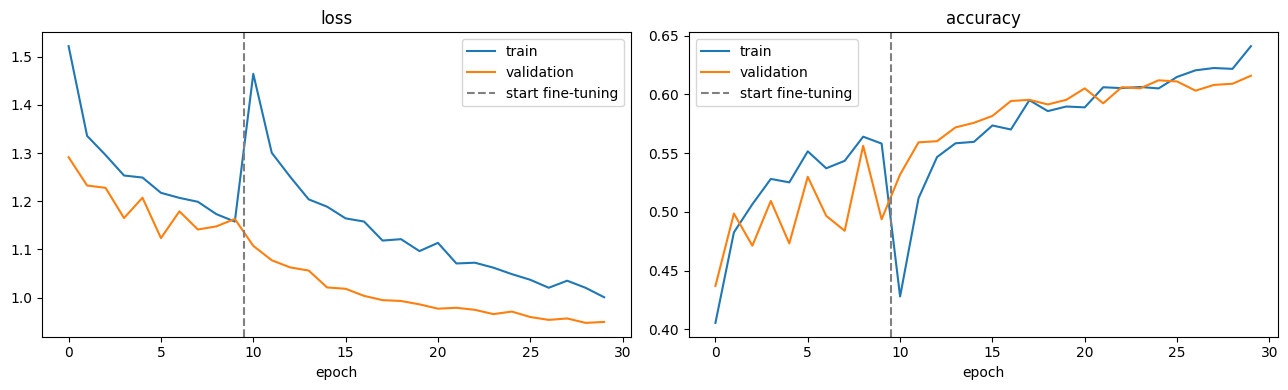

In [13]:
h = {k: hist1.history[k] + hist2.history[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
n1 = len(hist1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, metric in zip(ax, ["loss", "accuracy"]):
    a.plot(h[metric], label="train"); a.plot(h["val_" + metric], label="validation")
    a.axvline(n1 - 0.5, color="grey", ls="--", label="start fine-tuning")
    a.set_title(metric); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

### Save the model

The trained model replaces `models/diabetic_retinopathy_mobilenet.h5`, the file the API serves and retraining starts from. The model that was deployed before is copied to `models/experiments/deployed_before_notebook.h5` so the two can be compared in section 4.

In [14]:
PREVIOUS = ROOT / "models" / "experiments" / "deployed_before_notebook.h5"
if MODEL_PATH.exists() and not PREVIOUS.exists():
    PREVIOUS.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(MODEL_PATH, PREVIOUS)
save_model(model, MODEL_PATH)
print("saved", MODEL_PATH.relative_to(ROOT), f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

saved models/diabetic_retinopathy_mobilenet.h5 (24.9 MB)


## 4. Model testing

Metrics are computed on the two **held-out test sets**:

- **APTOS test** (550 images): same source as most of the training data
- **EyePACS test** (300 images, 60 per grade): different clinics and cameras, which tests how well the model generalises

Metrics: **accuracy**, **loss** (cross-entropy), **precision**, **recall** and **F1**, macro-averaged so every grade counts equally however rare it is, plus per-grade reports and confusion matrices.

In [15]:
def evaluate(m, x, y_true):
    probs = m.predict(x, batch_size=64, verbose=0)
    y_pred = probs.argmax(axis=1)
    loss = float(keras.losses.SparseCategoricalCrossentropy()(y_true, probs).numpy())
    return {
        "n_images": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "loss": loss,
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "classification_report": classification_report(y_true, y_pred, labels=list(range(5)), target_names=NAMES,
                                                       zero_division=0, output_dict=True),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(5))).tolist(),
    }

results = {
    "validation": evaluate(model, X_val, y_val),
    "aptos_test": evaluate(model, X_aptos_test, y_aptos_test),
    "eyepacs_test": evaluate(model, X_eye_test, y_eye_test),
}
summary = pd.DataFrame({k: {m: v[m] for m in ["n_images", "accuracy", "loss", "precision_macro", "recall_macro",
                                              "f1_macro", "f1_weighted"]} for k, v in results.items()}).T
display(summary)

,n_images,accuracy,loss,precision_macro,recall_macro,f1_macro,f1_weighted
validation,1023.0,0.609,0.928,0.582,0.575,0.560,0.622
aptos_test,550.0,0.751,0.645,0.582,0.571,0.568,0.752
eyepacs_test,300.0,0.423,1.403,0.372,0.423,0.370,0.370



aptos_test


,precision,recall,f1-score,support
No_DR,0.957,0.974,0.965,271.0
Mild,0.516,0.589,0.550,56.0
Moderate,0.655,0.607,0.630,150.0
Severe,0.227,0.345,0.274,29.0
Proliferate_DR,0.556,0.341,0.423,44.0
macro avg,0.582,0.571,0.568,550.0
weighted avg,0.759,0.751,0.752,550.0



eyepacs_test


,precision,recall,f1-score,support
No_DR,0.393,0.183,0.250,60.0
Mild,0.319,0.750,0.448,60.0
Moderate,0.000,0.000,0.000,60.0
Severe,0.450,0.600,0.514,60.0
Proliferate_DR,0.700,0.583,0.636,60.0
macro avg,0.372,0.423,0.370,300.0
weighted avg,0.372,0.423,0.370,300.0


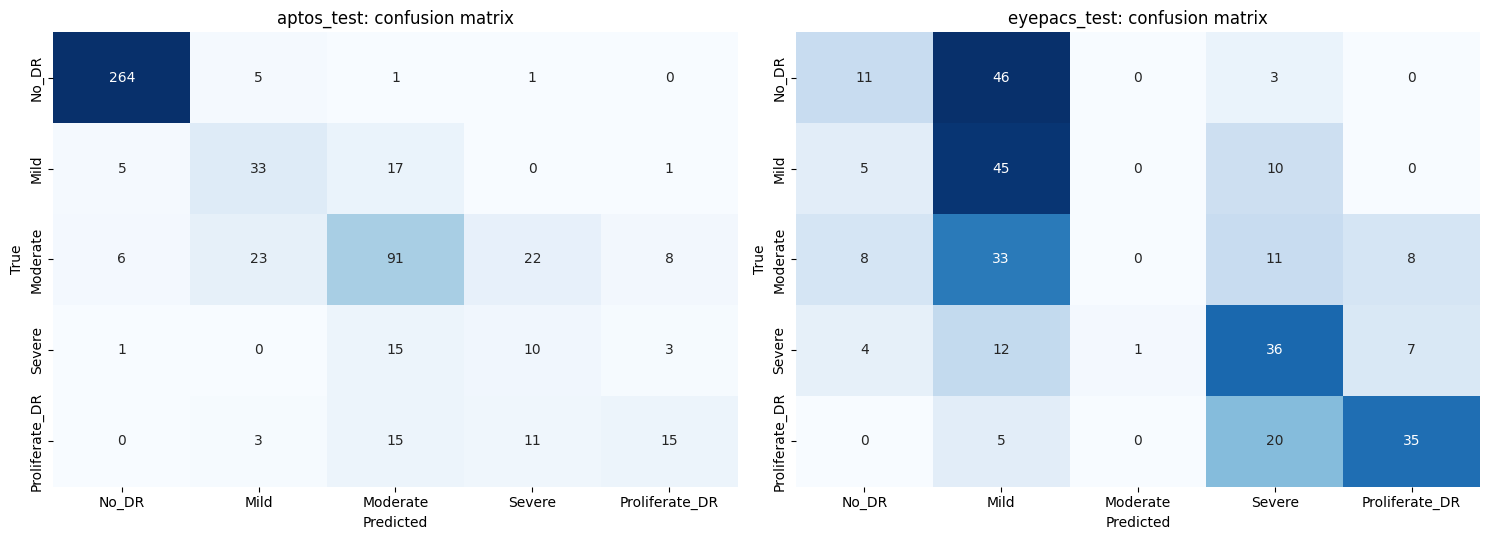

In [16]:
for name in ["aptos_test", "eyepacs_test"]:
    rep = pd.DataFrame(results[name]["classification_report"]).T
    print(f"\n{name}")
    display(rep.loc[NAMES + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, name in zip(ax, ["aptos_test", "eyepacs_test"]):
    cm = np.array(results[name]["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=NAMES, yticklabels=NAMES, ax=a, cbar=False)
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(f"{name}: confusion matrix")
plt.tight_layout(); plt.show()

### 4.1 Hyperparameter tuning

Before settling on this recipe, six training set-ups were compared with `scripts/train_model.py` and `scripts/evaluate.py`, all scored on the same held-out test sets (results in `models/experiments/`):

| Training data | Augment | Epochs (max) | APTOS F1 | EyePACS F1 |
|---------------|---------|--------------|----------|------------|
| APTOS, 400/class | – | 10 | 0.513 | 0.177 |
| APTOS, all | – | 20 | 0.538 | 0.172 |
| APTOS, all | ✓ | 30 | 0.451 | 0.136 |
| APTOS + EyePACS, 400/class | – | 10 | 0.501 | 0.309 |
| APTOS all + EyePACS | – | 20 | 0.520 | 0.329 |
| **APTOS all + EyePACS (chosen)** | ✓ | 30 | **0.543** | **0.369** |

Using all APTOS images helps. EyePACS images only pay off together with augmentation and a longer training budget. The chosen set-up matches the best APTOS-only model on APTOS and doubles the F1 on photos from other cameras.

## 5. Prediction functions

`src/prediction.py` is the code behind the API's `POST /predict`: it loads the saved `.h5`, runs `preprocess_image`, and returns the grade, its confidence and the probability of every grade.

In [18]:
from src.prediction import clear_model_cache, predict_image
print(inspect.getsource(predict_image))
clear_model_cache()   # make sure the freshly saved model is loaded

def predict_image(
    source: Union[str, Path, bytes],
    *,
    model=None,
    model_path: Optional[Path] = None,
) -> dict:
    model = model or get_model(model_path)
    tensor = preprocess_image(source)
    batch = np.expand_dims(tensor, axis=0)
    probs = model.predict(batch, verbose=0)[0]
    pred_id = int(np.argmax(probs))
    return {
        "class_id": pred_id,
        "class_name": CLASS_NAMES[pred_id],
        "confidence": float(probs[pred_id]),
        "probabilities": {CLASS_NAMES[i]: float(p) for i, p in enumerate(probs)},
    }



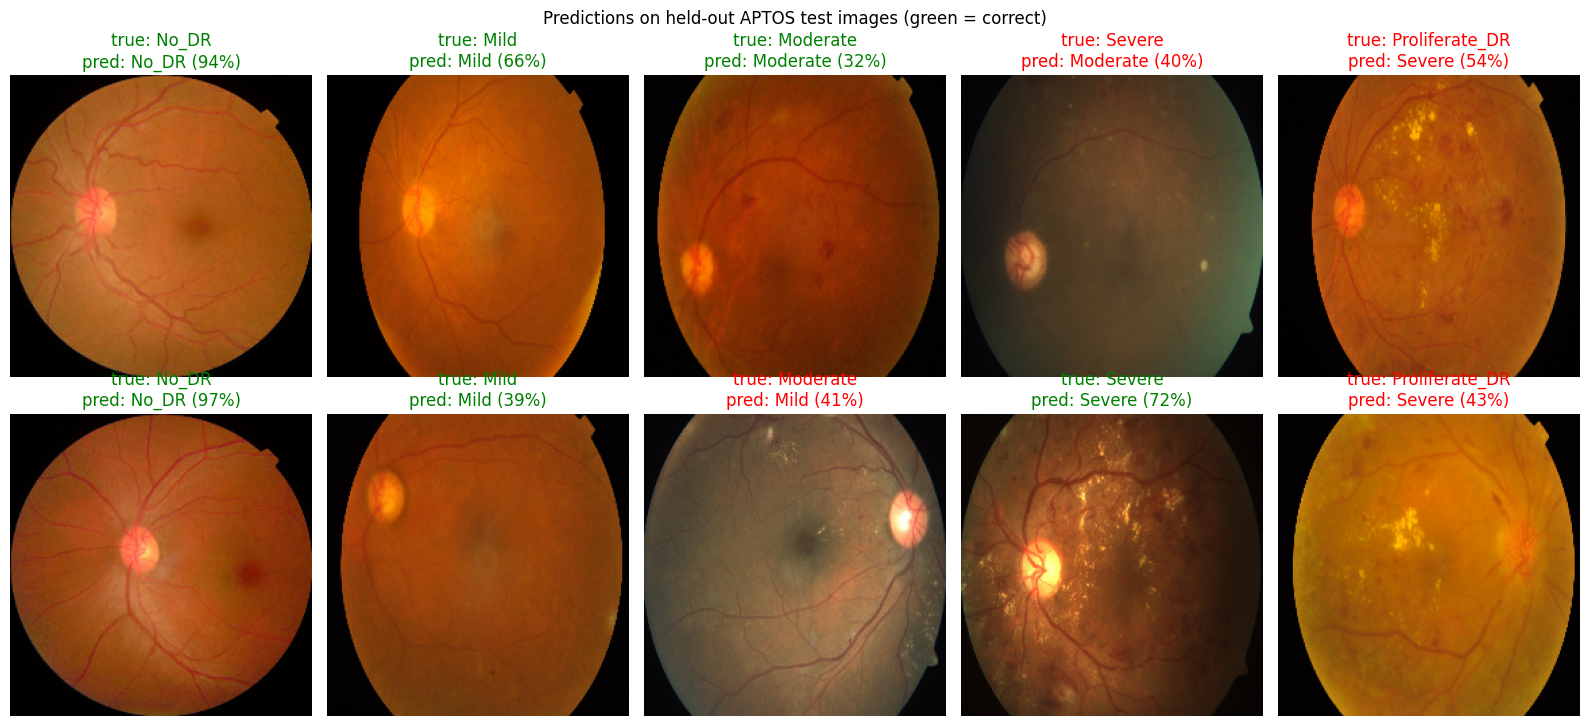

,image,true,predicted,confidence
0,00395.png,No_DR,No_DR,0.944
1,02870.png,No_DR,No_DR,0.970
2,01606.png,Mild,Mild,0.657
3,03599.png,Mild,Mild,0.391
4,02377.png,Moderate,Moderate,0.325
5,00280.png,Moderate,Mild,0.408
6,00543.png,Severe,Moderate,0.397
7,01827.png,Severe,Severe,0.720
8,02609.png,Proliferate_DR,Severe,0.541
9,02646.png,Proliferate_DR,Severe,0.434


probabilities for the last image: {'No_DR': 0.0, 'Mild': 0.012, 'Moderate': 0.172, 'Severe': 0.434, 'Proliferate_DR': 0.382}


In [19]:
rng = np.random.default_rng(SEED)
picks = []
for label in range(5):
    idx = np.flatnonzero(y_aptos_test == label)
    picks += list(rng.choice(idx, size=2, replace=False))

fig, axes = plt.subplots(2, 5, figsize=(16, 7.5))
rows = []
for a, i in zip(axes.T.flatten(), picks):
    path, true = aptos_test_paths[i], NAMES[y_aptos_test[i]]
    out = predict_image(path)                       # same call the API makes
    ok = out["class_name"] == true
    rows.append({"image": path.name, "true": true, "predicted": out["class_name"], "confidence": out["confidence"]})
    a.imshow(load_image_rgb(path)); a.axis("off")
    a.set_title(f"true: {true}\npred: {out['class_name']} ({out['confidence']:.0%})", color="green" if ok else "red")
plt.suptitle("Predictions on held-out APTOS test images (green = correct)"); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))
print("probabilities for the last image:", {k: round(v, 3) for k, v in out["probabilities"].items()})

### Save the metrics

The test results are written to `models/metrics.json`, which the README reports.

In [20]:
apt = results["aptos_test"]
metrics = {
    "model": "MobileNetV2 (ImageNet) fine-tuned; APTOS 2019 (all train images) + EyePACS sample, augmented",
    "evaluated_on": "data/splits/aptos_test — 550 APTOS images never used for training (see data/README.md)",
    **{k: apt[k] for k in ["accuracy", "loss", "precision_macro", "recall_macro", "f1_macro",
                           "classification_report", "confusion_matrix"]},
    "val_loss": results["validation"]["loss"],
    "test_sets": {k: results[k] for k in ["aptos_test", "eyepacs_test"]},
    "training": {
        "notebook": "notebook/diabetic_retinopathy.ipynb",
        "data": f"data/splits/mixed_train ({len(y_train) + len(y_val):,} images; 20% used for validation)",
        "epochs_head": EPOCHS_HEAD, "epochs_finetune": EPOCHS_FT, "patience": PATIENCE,
        "epochs_ran": [len(hist1.history["loss"]), len(hist2.history["loss"])],
        "validation_accuracy": results["validation"]["accuracy"],
        "validation_f1_macro": results["validation"]["f1_macro"],
    },
}
(ROOT / "models" / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("wrote models/metrics.json")

wrote models/metrics.json


## 6. Conclusions

- **APTOS test (550 unseen images):** accuracy **0.751**, loss 0.645, macro precision 0.582, recall 0.571, **F1 0.568** (weighted F1 0.752).
- **No_DR vs disease is reliable:** No_DR F1 0.97. Only 12 of 279 diseased APTOS test images were called No_DR, which matters most for screening, because a missed case is worse than an extra referral.
- **The hardest part is telling the middle grades apart.** Most errors are between neighbouring grades: 15 of 29 Severe images were predicted Moderate (both mean "refer to a specialist"), and Proliferate_DR is often called Severe. Severe has only 29 test images, so its score is noisy.
- **Other cameras (EyePACS test):** accuracy 0.423, F1 0.370. That is weaker but well above chance (0.20). The model separates Severe and Proliferate_DR on these photos (F1 0.51 / 0.64), but it calls most EyePACS No_DR and Moderate images Mild. Closing this camera gap would need more EyePACS training data. Uploading such images and retraining through the app is how the deployed model can be improved.
- **Optimization:** transfer learning, two-phase fine-tuning, dropout + L2, augmentation, class weights, Adam with ReduceLROnPlateau and early stopping. Validation loss kept falling through phase 2 without overfitting (train and validation curves stay close).
- Compared with the previously deployed model (same recipe, trained by script), this run scores slightly higher on APTOS (F1 0.568 vs 0.543) and the same on EyePACS (0.370 vs 0.369). That gap is within run-to-run noise.
